# Lab assignment №1, part 3

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the third part of the assignment. First and second parts are waiting for you in the same directory.*__

##  Part 3. SVM and kernels

Kernels concept get adopted in variety of ML algorithms (e.g. Kernel PCA, Gaussian Processes, kNN, ...).

So in this task you are to examine kernels for SVM algorithm applied to rather simple artificial datasets.

To make it clear: we will work with the classification problem through the whole notebook.

In [1]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import numpy as np

Let's generate our dataset and take a look on it.

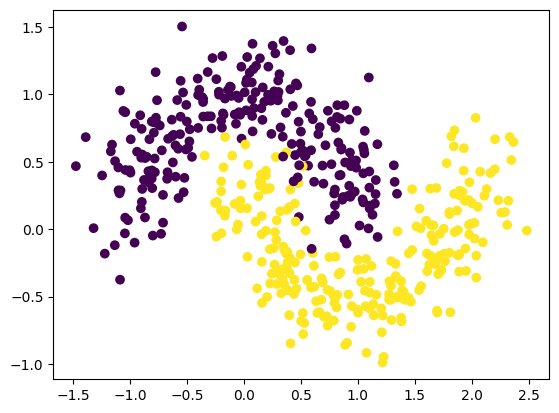

In [2]:
moons_points, moons_labels = make_moons(n_samples=500, noise=0.2, random_state=42)
plt.scatter(moons_points[:, 0], moons_points[:, 1], c=moons_labels)

## 1.1 Pure models.
First let's try to solve this case with good old Logistic Regression and simple (linear kernel) SVM classifier.

Train LR and SVM classifiers (choose params by hand, no CV or intensive grid search neeeded) and plot their decision regions. Calculate one preffered classification metric.

Describe results in one-two sentences.

_Tip:_ to plot classifiers decisions you colud use either sklearn examples ([this](https://scikit-learn.org/stable/auto_examples/neural_networks/plot_mlp_alpha.html#sphx-glr-auto-examples-neural-networks-plot-mlp-alpha-py) or any other) and mess with matplotlib yourself or great [mlxtend](https://github.com/rasbt/mlxtend) package (see their examples for details)

_Pro Tip:_ wirte function `plot_decisions` taking a dataset and an estimator and plotting the results cause you want to use it several times below

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from mlxtend.plotting import plot_decision_regions

from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import train_test_split

lr = LogisticRegression(solver='saga', tol=1e-3, max_iter=500, C=1, random_state=42) # add some params
svm = SVC(kernel='linear', C=0.1) # here too

X_train, X_test, y_train, y_test = train_test_split(
    moons_points,
    moons_labels,
    test_size=0.30,
    random_state=42,
    stratify=moons_labels
)

lr.fit(X_train, y_train)
svm.fit(X_train, y_train)

y_pred_logreg = lr.predict(X_test)
y_pred_svm = svm.predict(X_test)

f1_logreg = f1_score(y_test, y_pred_logreg)
f1_svm = f1_score(y_test, y_pred_svm)

acc_logreg = accuracy_score(y_test, y_pred_logreg)
acc_svm = accuracy_score(y_test, y_pred_svm)

print(f"LogReg F1: {f1_logreg:.4f}")
print(f"Linear SVM F1: {f1_svm:.4f}")
print(f"LogReg accuracy: {acc_logreg:.4f}")
print(f"Linear SVM accuracy: {acc_svm:.4f}")

LogReg F1: 0.8591
Linear SVM F1: 0.8609
LogReg accuracy: 0.8600
Linear SVM accuracy: 0.8600


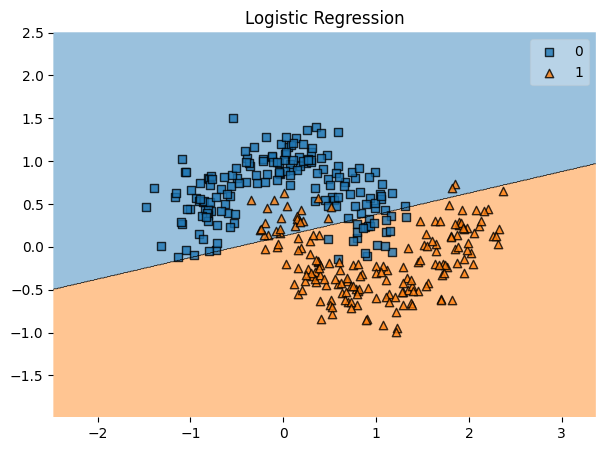

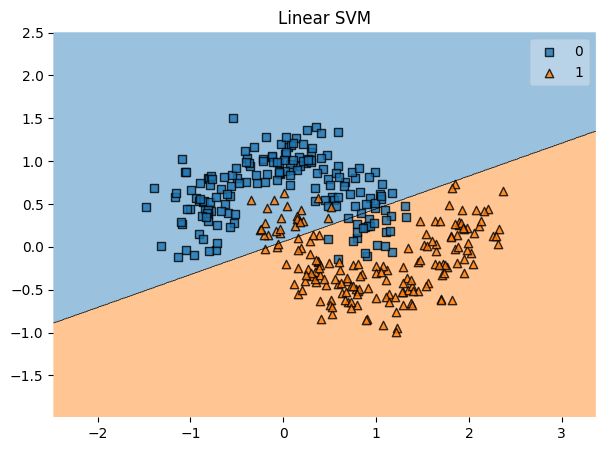

In [8]:
plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=lr)
plt.title("Logistic Regression")
plt.show()

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm)
plt.title("Linear SVM")
plt.show()

Логистическая регрессия и линейный SVM показали близкое качество классификации: F1 = 0.8591 и F1 = 0.8609. При ручном подборе параметра C (перебор был небольшим) наилучшие результаты среди проверенных значений получены при C=1 для логистической регрессии и C=0.1 для SVM. Обе модели построили линейные границы решений, однако их наклон отличается: у SVM он чуть больше. Из-за нелинейной структуры данных полностью разделить классы не удалось

## 1.2 Kernel tirck

Now use different kernels (`poly`, `rbf`, `sigmoid`) on SVC to get better results. Play `degree` parameter and others.

For each kernel estimate optimal params, plot decision regions, calculate metric you've chosen eariler.

Write couple of sentences on:

* What have happenned with classification quality?
* How did decision border changed for each kernel?
* What `degree` have you chosen and why?

### Посмотрим на RBF

In [11]:
# rbf
svm_rbf = SVC(kernel='rbf', C=1, gamma='scale')
svm_rbf.fit(X_train, y_train)
y_pred_svm_rbf = svm_rbf.predict(X_test)

f1_svm_rbf = f1_score(y_test, y_pred_svm_rbf)
accuracy_svm_rbf = accuracy_score(y_test, y_pred_svm_rbf)


print(f"RBF SVM F1: {f1_svm_rbf:.4f}")
print(f"RBF SVM accuracy: {accuracy_svm_rbf:.4f}")

RBF SVM F1: 0.9865
RBF SVM accuracy: 0.9867


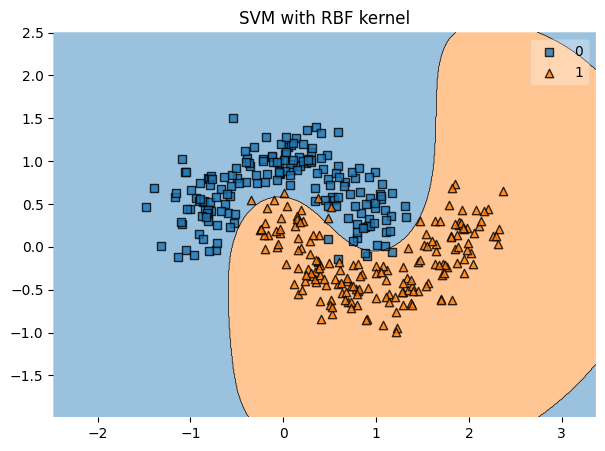

In [12]:
plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm_rbf)
plt.title("SVM with RBF kernel")
plt.show()

RBF SVM F1: 0.8725
RBF SVM accuracy: 0.8733


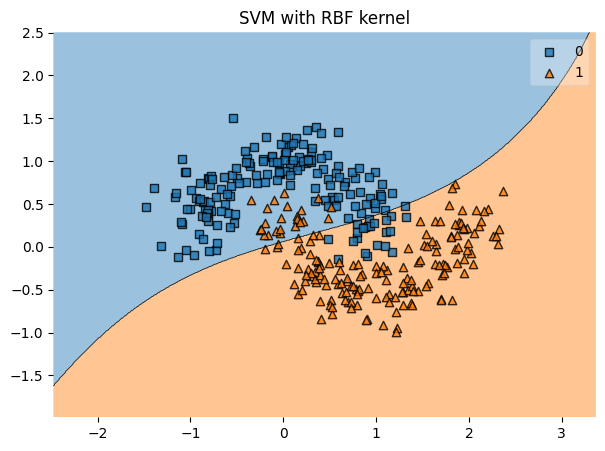

In [14]:
# пошатаем гамму (0.1)
svm_rbf = SVC(kernel='rbf', C=1, gamma=0.1)
svm_rbf.fit(X_train, y_train)
y_pred_svm_rbf = svm_rbf.predict(X_test)

f1_svm_rbf = f1_score(y_test, y_pred_svm_rbf)
accuracy_svm_rbf = accuracy_score(y_test, y_pred_svm_rbf)


print(f"RBF SVM F1: {f1_svm_rbf:.4f}")
print(f"RBF SVM accuracy: {accuracy_svm_rbf:.4f}")

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm_rbf)
plt.title("SVM with RBF kernel")
plt.show()

RBF SVM F1: 0.9865
RBF SVM accuracy: 0.9867


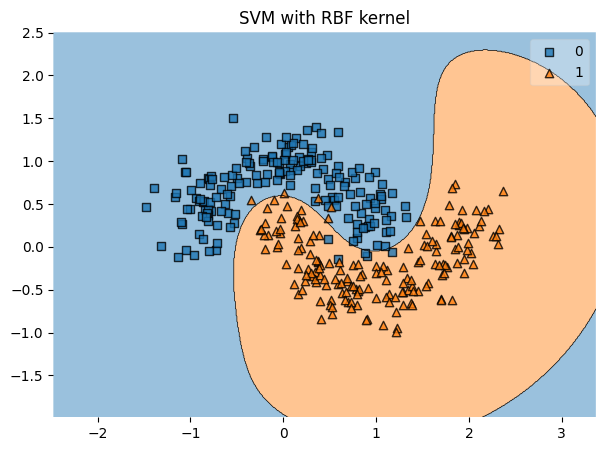

In [15]:
# пошатаем гамму (1)
svm_rbf = SVC(kernel='rbf', C=1, gamma=1)
svm_rbf.fit(X_train, y_train)
y_pred_svm_rbf = svm_rbf.predict(X_test)

f1_svm_rbf = f1_score(y_test, y_pred_svm_rbf)
accuracy_svm_rbf = accuracy_score(y_test, y_pred_svm_rbf)


print(f"RBF SVM F1: {f1_svm_rbf:.4f}")
print(f"RBF SVM accuracy: {accuracy_svm_rbf:.4f}")

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm_rbf)
plt.title("SVM with RBF kernel")
plt.show()

RBF SVM F1: 0.9799
RBF SVM accuracy: 0.9800


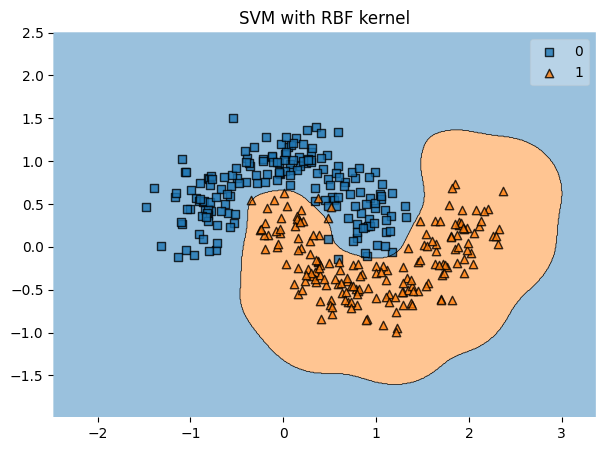

In [16]:
# пошатаем гамму (10)
svm_rbf = SVC(kernel='rbf', C=1, gamma=10)
svm_rbf.fit(X_train, y_train)
y_pred_svm_rbf = svm_rbf.predict(X_test)

f1_svm_rbf = f1_score(y_test, y_pred_svm_rbf)
accuracy_svm_rbf = accuracy_score(y_test, y_pred_svm_rbf)


print(f"RBF SVM F1: {f1_svm_rbf:.4f}")
print(f"RBF SVM accuracy: {accuracy_svm_rbf:.4f}")

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm_rbf)
plt.title("SVM with RBF kernel")
plt.show()

Переход к RBF-ядру сильно увеличил F1 (и accuracy) - примерно на 0.13.
При увеличении gamma с 0.1 до 1 качество классификации значительно улучшилось: F1 вырос с 0.8725 до 0.9865. При gamma=10 качество немного снизилось, а граница решений стала более сложной. Среди рассмотренных значений gamma=1 показало лучший результат.

### Посмотрим на POLY

POLY SVM F1: 0.7640
POLY SVM accuracy: 0.7200


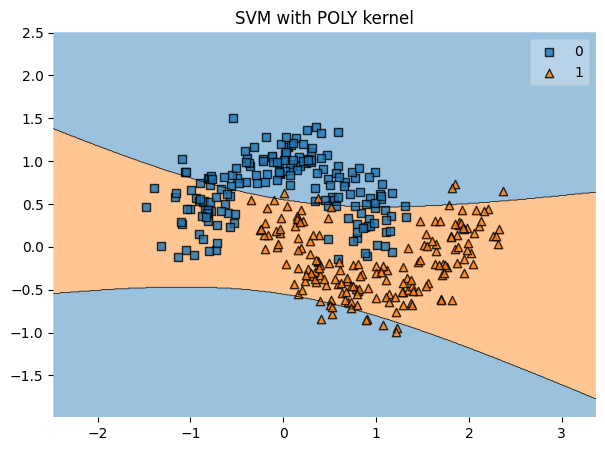

In [17]:
# шатаем degree (2)
svm_poly = SVC(kernel='poly', C=1, degree=2)
svm_poly.fit(X_train, y_train)
y_pred_svm_poly = svm_poly.predict(X_test)

f1_svm_poly = f1_score(y_test, y_pred_svm_poly)
accuracy_svm_poly = accuracy_score(y_test, y_pred_svm_poly)


print(f"POLY SVM F1: {f1_svm_poly:.4f}")
print(f"POLY SVM accuracy: {accuracy_svm_poly:.4f}")

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm_poly)
plt.title("SVM with POLY kernel")
plt.show()

POLY SVM F1: 0.8718
POLY SVM accuracy: 0.8667


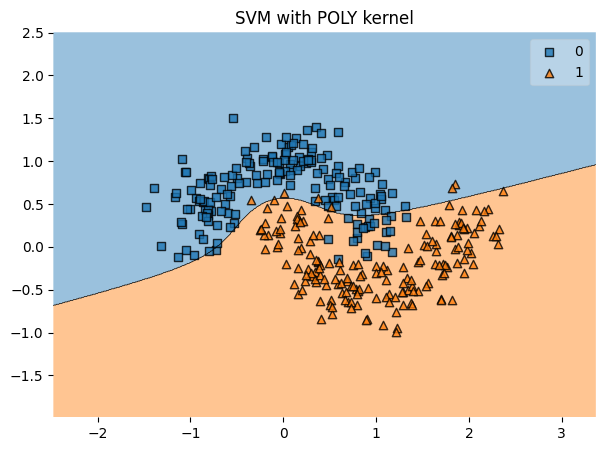

In [18]:
# шатаем degree (3)
svm_poly = SVC(kernel='poly', C=1, degree=3)
svm_poly.fit(X_train, y_train)
y_pred_svm_poly = svm_poly.predict(X_test)

f1_svm_poly = f1_score(y_test, y_pred_svm_poly)
accuracy_svm_poly = accuracy_score(y_test, y_pred_svm_poly)


print(f"POLY SVM F1: {f1_svm_poly:.4f}")
print(f"POLY SVM accuracy: {accuracy_svm_poly:.4f}")

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm_poly)
plt.title("SVM with POLY kernel")
plt.show()

POLY SVM F1: 0.7821
POLY SVM accuracy: 0.7400


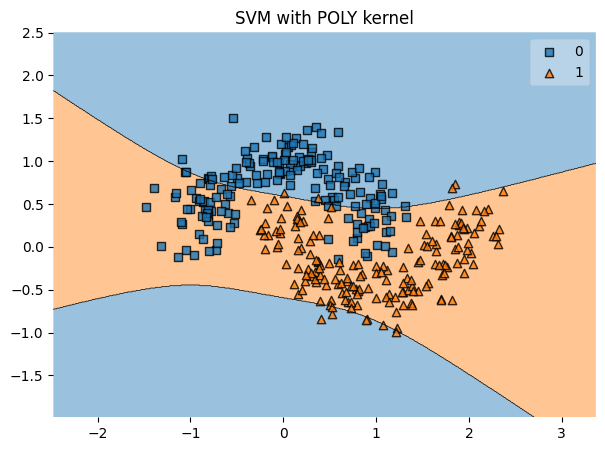

In [19]:
# шатаем degree (4)
svm_poly = SVC(kernel='poly', C=1, degree=4)
svm_poly.fit(X_train, y_train)
y_pred_svm_poly = svm_poly.predict(X_test)

f1_svm_poly = f1_score(y_test, y_pred_svm_poly)
accuracy_svm_poly = accuracy_score(y_test, y_pred_svm_poly)


print(f"POLY SVM F1: {f1_svm_poly:.4f}")
print(f"POLY SVM accuracy: {accuracy_svm_poly:.4f}")

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm_poly)
plt.title("SVM with POLY kernel")
plt.show()

POLY SVM F1: 0.9865
POLY SVM accuracy: 0.9867


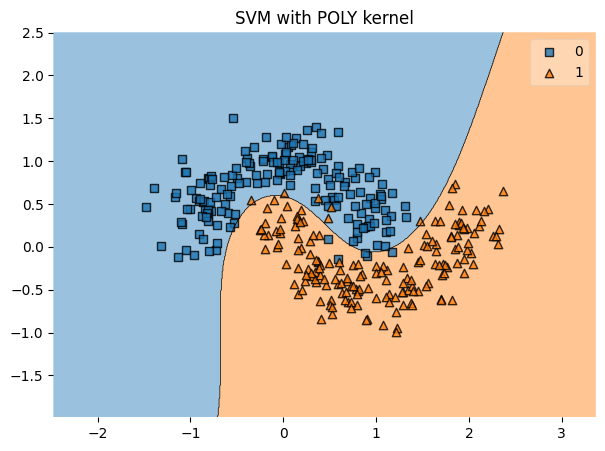

In [20]:
# меняем coef
svm_poly = SVC(kernel='poly', C=1, degree=3, gamma='scale', coef0=1)
svm_poly.fit(X_train, y_train)
y_pred_svm_poly = svm_poly.predict(X_test)

f1_svm_poly = f1_score(y_test, y_pred_svm_poly)
accuracy_svm_poly = accuracy_score(y_test, y_pred_svm_poly)


print(f"POLY SVM F1: {f1_svm_poly:.4f}")
print(f"POLY SVM accuracy: {accuracy_svm_poly:.4f}")

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm_poly)
plt.title("SVM with POLY kernel")
plt.show()

При использовании poly ядра лучший результат среди проверенных степеней получен при `degree=3`. Изменение `coef0` с 0 на 1 значительно улучшило качество классификации: F1 вырос с 0.8718 до 0.9865.

Граница решений стала лучше учитывать нелинейную структуру данных. **Итоговое качество POLY (F1 = 0.9865, Accuracy = 0.9867) совпало с результатом RBF**, хотя формы границ решений отличаются

### Посмотрим на SIGMOID

Sigmoid SVM F1: 0.6104
Sigmoid SVM Accuracy: 0.6000


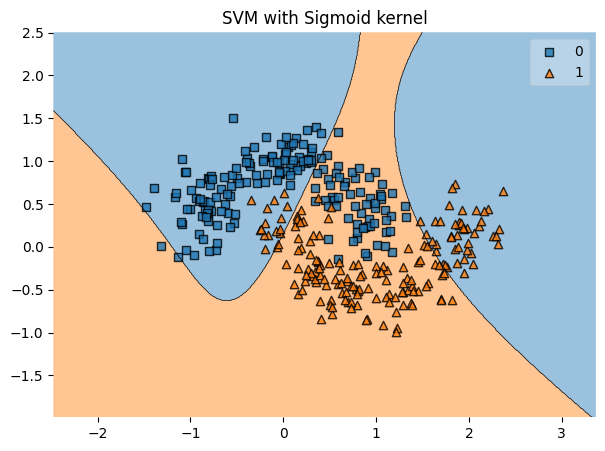

In [24]:
svm_sigmoid = SVC(kernel='sigmoid', C=1, gamma=1, coef0=0)

svm_sigmoid.fit(X_train, y_train)
y_pred_svm_sigmoid = svm_sigmoid.predict(X_test)

f1_svm_sigmoid = f1_score(y_test, y_pred_svm_sigmoid)
accuracy_svm_sigmoid = accuracy_score(y_test, y_pred_svm_sigmoid)

print(f"Sigmoid SVM F1: {f1_svm_sigmoid:.4f}")
print(f"Sigmoid SVM Accuracy: {accuracy_svm_sigmoid:.4f}")

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm_sigmoid)
plt.title("SVM with Sigmoid kernel")
plt.show()

Sigmoid SVM F1: 0.5379
Sigmoid SVM Accuracy: 0.5533


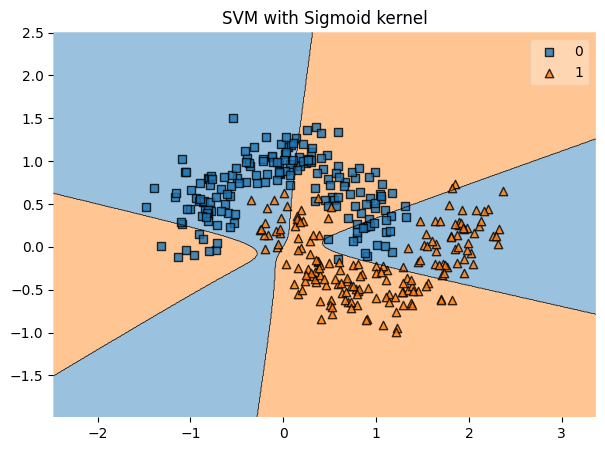

In [32]:
# в этой ячейке подбираю параметры
svm_sigmoid = SVC(kernel='sigmoid', C=1, gamma=10, coef0=0)

svm_sigmoid.fit(X_train, y_train)
y_pred_svm_sigmoid = svm_sigmoid.predict(X_test)

f1_svm_sigmoid = f1_score(y_test, y_pred_svm_sigmoid)
accuracy_svm_sigmoid = accuracy_score(y_test, y_pred_svm_sigmoid)

print(f"Sigmoid SVM F1: {f1_svm_sigmoid:.4f}")
print(f"Sigmoid SVM Accuracy: {accuracy_svm_sigmoid:.4f}")

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm_sigmoid)
plt.title("SVM with Sigmoid kernel")
plt.show()

Sigmoid SVM F1: 0.8553
Sigmoid SVM Accuracy: 0.8533


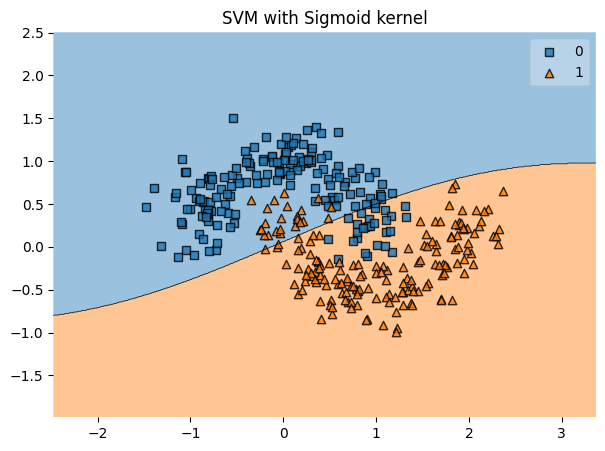

In [62]:
svm_sigmoid = SVC(kernel='sigmoid', C=1, gamma=0.1, coef0=0)

svm_sigmoid.fit(X_train, y_train)
y_pred_svm_sigmoid = svm_sigmoid.predict(X_test)

f1_svm_sigmoid = f1_score(y_test, y_pred_svm_sigmoid)
accuracy_svm_sigmoid = accuracy_score(y_test, y_pred_svm_sigmoid)

print(f"Sigmoid SVM F1: {f1_svm_sigmoid:.4f}")
print(f"Sigmoid SVM Accuracy: {accuracy_svm_sigmoid:.4f}")

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=svm_sigmoid)
plt.title("SVM with Sigmoid kernel")
plt.show()

Sigmoid-ядро чувствительно к параметру `gamma`. При его увеличении граница решений становилась сложнее, но качество классификации снижалось

Лучший результат среди проверенных параметров получен при `gamma=0.1`, `coef0=0`: **F1 = 0.8553, Accuracy = 0.8533**. Дополнительный подбор C, gamma и coef0 не дал улучшения на тестовой выборке. Лучший наблюдаемый F1 остался равным 0.8553

Sigmoid показал результат, близкий к линейным моделям, но сильно проигрывает RBF и POLY, тк его граница решений хуже соответствует нелинейной структуре данных

## 1.3 Simpler solution (of a kind)
What is we could use Logisitc Regression to successfully solve this task?

Feature generation is a thing to help here. Different techniques of feature generation are used in real life, couple of them will be covered in additional lectures.

In particular case simple `PolynomialFeatures` ([link](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)) are able to save the day.

Generate the set of new features, train LR on it, plot decision regions, calculate metric.

* Comare SVM's results with this solution (quality, borders type)
* What degree of PolynomialFeatures have you used? Compare with same SVM kernel parameter.

In [38]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline

# полиномиальные признаки
poly = PolynomialFeatures(degree=4, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model_poly = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(C=1, max_iter=1000))
])

model_poly.fit(X_train_poly, y_train)
y_pred_poly = model_poly.predict(X_test_poly)

f1_poly = f1_score(y_test, y_pred_poly)
accuracy_poly = accuracy_score(y_test, y_pred_poly)

print(f"Polynomial LR F1: {f1_poly:.4f}")
print(f"Polynomial LR Accuracy: {accuracy_poly:.4f}")

Polynomial LR F1: 0.9655
Polynomial LR Accuracy: 0.9667


In [40]:
import pandas as pd

# сделаем цикл, чтобы посмотреть разные degree
results = []

for degree in range(1, 11):

    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(C=1, max_iter=2000))
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        'degree': degree,
        'F1': f1_score(y_test, y_pred),
        'Accuracy': accuracy_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

   degree      F1  Accuracy
0       1  0.8514    0.8533
1       2  0.8514    0.8533
2       3  0.9306    0.9333
3       4  0.9655    0.9667
4       5  0.9865    0.9867
5       6  0.9865    0.9867
6       7  0.9865    0.9867
7       8  0.9865    0.9867
8       9  0.9865    0.9867
9      10  0.9865    0.9867


При увеличении `degree` качество логистической регрессии улучшалось: F1 вырос с 0.8514 при `degree=1` до 0.9865 при `degree=5`. Дальнейшее увеличение не увеличивает F1. Выберем **степень 5**

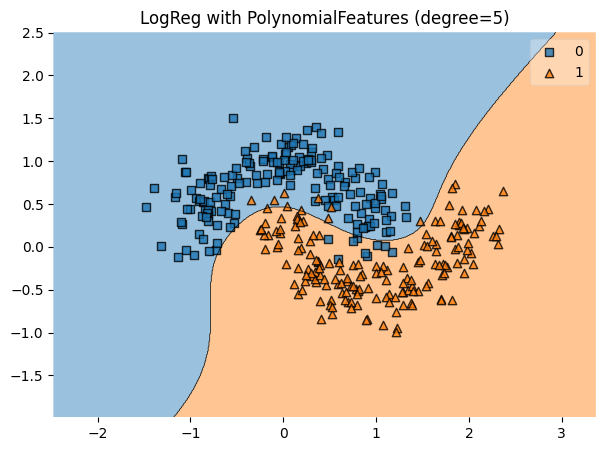

In [41]:
# строим границу решений
model_poly = Pipeline([
    ('poly', PolynomialFeatures(degree=5, include_bias=False)),
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(C=1, max_iter=2000))
])

model_poly.fit(X_train, y_train)

plt.figure(figsize=(7, 5))
plot_decision_regions(X=X_train, y=y_train, clf=model_poly)
plt.title("LogReg with PolynomialFeatures (degree=5)")
plt.show()

За счет добавления полиномиальных признаков улучшилось качество регрессии, граница решений стала нелинейной. При `degree=5` получены F1 = 0.9865 и Accuracy = 0.9867.

Для логистической регрессии наилучший результат получен при степени 5, а для POLY-SVM — при степени 3 (coef0=1)

Качество совпало с результатами RBF-SVM и POLY-SVM, хотя формы границ решений отличаются. Таким образом, добавление полиномиальных признаков позволяет решать нелинейную задачу классификации с помощью логистической регрессии

## Вывод

Мы подтвердили, что линейные модели (LR и Linear SVM) плохо учитывают нелинейную структуру данных. Обе модели показали близкое качество классификации F1 ≈ 0.86.

Использование нелинейных ядер значительно улучшило результаты. **RBF и POLY** достигли F1 = 0.9865, тогда как Sigmoid показал более низкое качество (F1 = 0.8553). При этом выбор гиперпараметров существенно влиял как на качество, так и на форму границ решений.

Добавление PolynomialFeatures позволило обычной логистической регрессии также построить нелинейную границу и достичь **F1 = 0.9865**.

## 1.4 Harder problem

Let's make this task a bit more challenging via upgrading dataset:

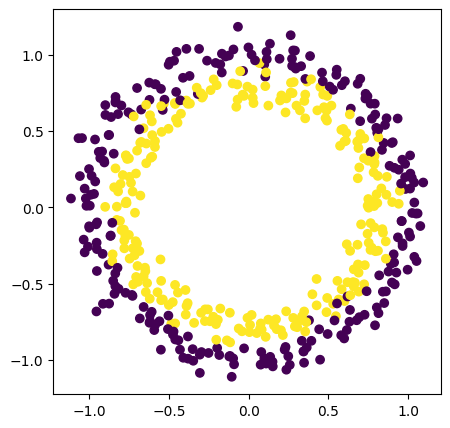

In [42]:
from sklearn.datasets import make_circles

circles_points, circles_labels = make_circles(n_samples=500, noise=0.06, random_state=42)

plt.figure(figsize=(5, 5))
plt.scatter(circles_points[:, 0], circles_points[:, 1], c=circles_labels)

And even more:

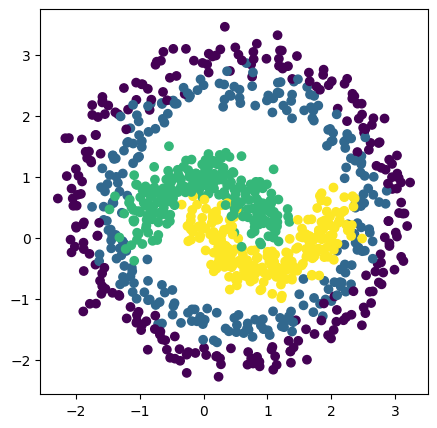

In [43]:
points = np.vstack((circles_points*2.5 + 0.5, moons_points))
labels = np.hstack((circles_labels, moons_labels + 2)) # + 2 to distinct moons classes

plt.figure(figsize=(5, 5))
plt.scatter(points[:, 0], points[:, 1], c=labels)

Now do your best using all the approaches above!

Tune LR with generated features, SVM with appropriate kernel of your choice. You may add some of your loved models to demonstrate their (and your) strength. Again plot decision regions, calculate metric.

Justify the results in a few phrases.

In [44]:
X_train_1_4, X_test_1_4, y_train_1_4, y_test_1_4 = train_test_split(
    points,
    labels,
    test_size=0.3,
    random_state=42,
    stratify=labels
)

### LR

In [47]:
model = Pipeline([
    ('poly', PolynomialFeatures(degree=5, include_bias=False)),
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(C=1, max_iter=2000))
])

model.fit(X_train_1_4, y_train_1_4)
y_pred = model.predict(X_test_1_4)

f1 = f1_score(y_test_1_4, y_pred, average='macro')
accuracy = accuracy_score(y_test_1_4, y_pred)

print(f"F1: {f1:.4f}")
print(f"Accuracy: {accuracy:.4f}")

F1: 0.8931
Accuracy: 0.8933


/usr/local/lib/python3.13/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


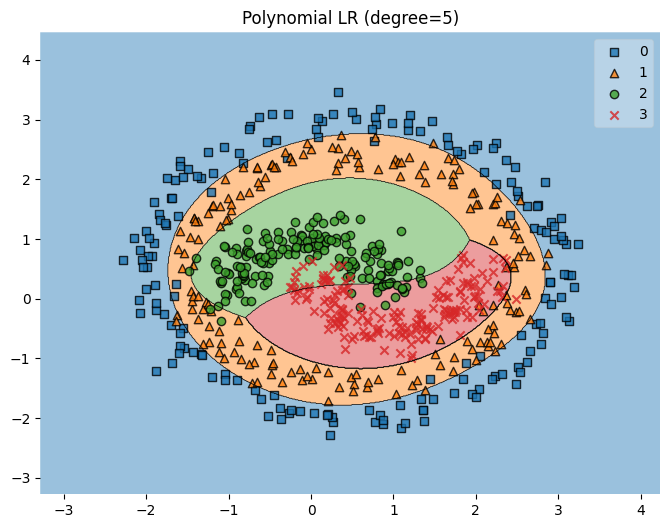

In [48]:
plt.figure(figsize=(8, 6))
plot_decision_regions(
    X=X_train_1_4,
    y=y_train_1_4,
    clf=model
)
plt.title("Polynomial LR (degree=5)")
plt.show()

Логистическая регрессия с полиномиальными признаками показала неплохое качество на более сложном датасете: **F1-macro = 0.8931, Accuracy = 0.8933**.

Модель смогла построить нелинейные границы, учитывающие структуру четырёх классов. Однако в центральной области классы 2 и 3 частично пересекаются, что приводит к снижению качества

### SVM

In [50]:
svm_rbf_1_4 = SVC(kernel='rbf', C=1, gamma='scale')

svm_rbf_1_4.fit(X_train_1_4, y_train_1_4)
y_pred_rbf_1_4 = svm_rbf_1_4.predict(X_test_1_4)

f1_rbf_1_4 = f1_score(y_test_1_4, y_pred_rbf_1_4, average='macro')
accuracy_rbf_1_4 = accuracy_score(y_test_1_4, y_pred_rbf_1_4)

print(f"F1: {f1_rbf_1_4:.4f}")
print(f"Accuracy: {accuracy_rbf_1_4:.4f}")

F1: 0.9098
Accuracy: 0.9100


/usr/local/lib/python3.13/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


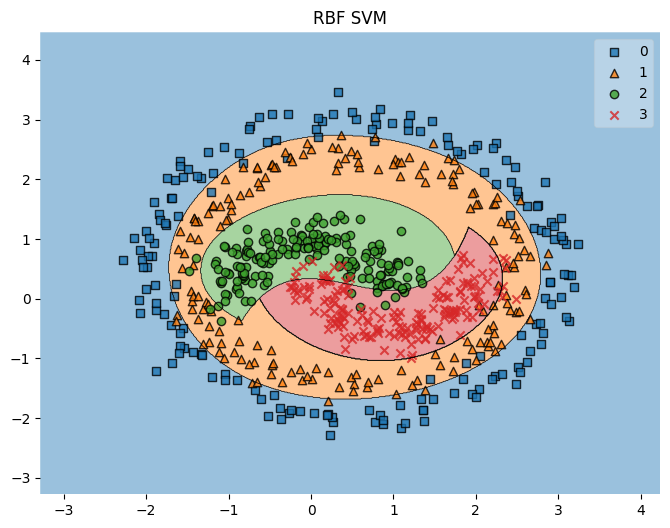

In [51]:
plt.figure(figsize=(8, 6))
plot_decision_regions(
    X=X_train_1_4,
    y=y_train_1_4,
    clf=svm_rbf_1_4
)
plt.title("RBF SVM")
plt.show()

RBF чуть лучше показала себя по сравнению с полиномиальной логистической регрессией, а границы RBF выглядят более плавными и лучше соответствуют расположению классов

**Попробуем покрутить параметры**- дополнительно выделим валидационную выборку из обучающей (а тестовую оставим для окончательной оценки)

In [54]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_1_4,
    y_train_1_4,
    test_size=0.25,
    random_state=42,
    stratify=y_train_1_4
)

results = []

for C in [0.1, 1, 10, 25, 50]:
    for gamma in [0.1, 1, 10, 'scale']:

        model = SVC(kernel='rbf', C=C, gamma=gamma)

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)

        results.append({
            'C': C,
            'gamma': gamma,
            'F1_macro': f1_score(y_val, y_pred, average='macro'),
            'Accuracy': accuracy_score(y_val, y_pred)
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

   C gamma  F1_macro  Accuracy
 0.1   0.1    0.6316    0.6457
 0.1     1    0.8059    0.8057
 0.1    10    0.7015    0.7371
 0.1 scale    0.7438    0.7486
 1.0   0.1    0.8684    0.8686
 1.0     1    0.9091    0.9086
 1.0    10    0.9093    0.9086
 1.0 scale    0.8860    0.8857
10.0   0.1    0.8741    0.8743
10.0     1    0.9202    0.9200
10.0    10    0.9034    0.9029
10.0 scale    0.9201    0.9200
25.0   0.1    0.8971    0.8971
25.0     1    0.9091    0.9086
25.0    10    0.8976    0.8971
25.0 scale    0.9204    0.9200
50.0   0.1    0.9086    0.9086
50.0     1    0.8973    0.8971
50.0    10    0.8976    0.8971
50.0 scale    0.9091    0.9086


При C=25, gamma='scale' получен максимальный F1-macro на валидации — 0.9204

Теперь обучим итоговую модель на всей обучающей выборке и оценим на тестовой:

F1: 0.9232
Accuracy: 0.9233


/usr/local/lib/python3.13/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


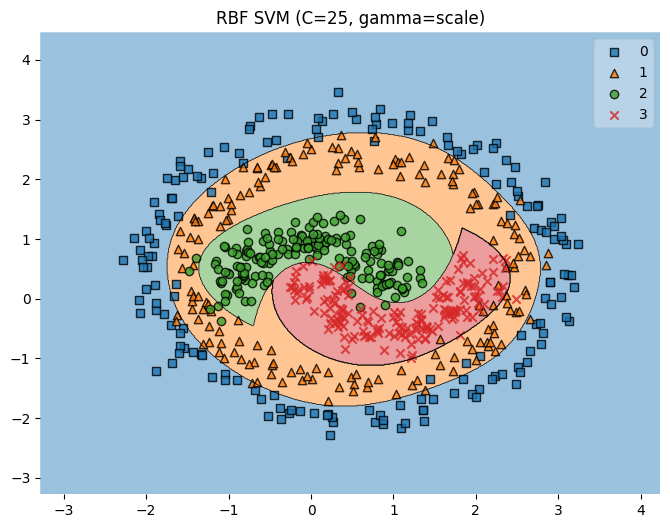

In [55]:
best_svm_rbf = SVC(kernel='rbf', C=25, gamma='scale')

best_svm_rbf.fit(X_train_1_4, y_train_1_4)
y_pred_best = best_svm_rbf.predict(X_test_1_4)

print("F1:", round(f1_score(y_test_1_4, y_pred_best, average='macro'), 4))
print("Accuracy:", round(accuracy_score(y_test_1_4, y_pred_best), 4))

plt.figure(figsize=(8, 6))
plot_decision_regions(
    X=X_train_1_4,
    y=y_train_1_4,
    clf=best_svm_rbf
)
plt.title("RBF SVM (C=25, gamma=scale)")
plt.show()

RBF с подобранными параметрами увеличил F1 с 0.9098 до 0.9232, Accuracy — с 0.9100 до 0.9233. Модель построила нелинейные границы, хорошо учитывающие структуру четырёх классов. Есть только частичное пересечение классов в центральной области

**Теперь повалидируем параметры лог регрессии на той же валидационной выборке**

In [58]:
results_lr = []

for degree in range(1, 11):
    for C in [0.1, 1, 10, 25, 50, 100]:

        model_lr = Pipeline([
            ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
            ('scaler', StandardScaler()),
            ('logreg', LogisticRegression(C=C, max_iter=2000))
        ])

        model_lr.fit(X_tr, y_tr)
        y_pred = model_lr.predict(X_val)

        results_lr.append({
            'degree': degree,
            'C': C,
            'F1_macro': f1_score(y_val, y_pred, average='macro'),
            'Accuracy': accuracy_score(y_val, y_pred)
        })

results_lr_df = pd.DataFrame(results_lr)
results_lr_df = results_lr_df.sort_values(by=['F1_macro', 'degree'], ascending=[False, True])

print(results_lr_df.head(15).round(4).to_string(index=False))

 degree     C  F1_macro  Accuracy
      7  50.0    0.9205    0.9200
      7 100.0    0.9205    0.9200
      8 100.0    0.9152    0.9143
      3 100.0    0.9150    0.9143
      6  50.0    0.9150    0.9143
      6 100.0    0.9150    0.9143
      7  25.0    0.9147    0.9143
      9 100.0    0.9097    0.9086
     10 100.0    0.9097    0.9086
      8  50.0    0.9095    0.9086
      9  50.0    0.9095    0.9086
      4  50.0    0.9093    0.9086
      4 100.0    0.9093    0.9086
      5  50.0    0.9093    0.9086
      5 100.0    0.9093    0.9086


При C=50, degree=7 получен максимальный F1-macro на валидации — 0.9205

Теперь обучим итоговую модель на всей обучающей выборке и оценим на тестовой:

F1: 0.9064
Accuracy: 0.9067


/usr/local/lib/python3.13/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


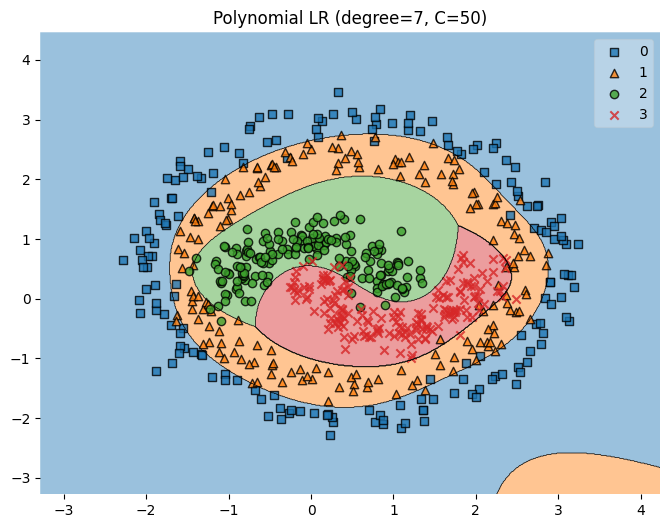

In [59]:
best_lr = Pipeline([
    ('poly', PolynomialFeatures(degree=7, include_bias=False)),
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(C=50, max_iter=5000))
])

best_lr.fit(X_train_1_4, y_train_1_4)

y_pred_best_lr = best_lr.predict(X_test_1_4)

print("F1:", round(f1_score(y_test_1_4, y_pred_best_lr, average='macro'), 4))
print("Accuracy:", round(accuracy_score(y_test_1_4, y_pred_best_lr), 4))

plt.figure(figsize=(8, 6))
plot_decision_regions(
    X=X_train_1_4,
    y=y_train_1_4,
    clf=best_lr
)
plt.title("Polynomial LR (degree=7, C=50)")
plt.show()

Polynomial LR с подобранными параметрами увеличил F1 с 0.8931 до 0.9064, Accuracy — с 0.8933 до 0.9067. Модель также построила нелинейные границы, хорошо учитывающие структуру четырёх классов. И все еще есть только частичное пересечение классов в центральной области

## Вывод
В задаче классификации четырёх классов обе модели смогли построить нелинейные границы решений. Подбор гиперпараметров улучшил качество логистической регрессии с полиномиальными признаками: F1-macro вырос с 0.8931 до 0.9064 при `degree=7`, `C=50`.

Наилучший результат показал **RBF-SVM** с `C=25`, `gamma='scale'`: F1-macro = 0.9232, Accuracy = 0.9233. Его граница лучше учитывает сложную структуру данных, однако пересечение классов в центральной области по-прежнему приводит к ошибкам классификации.